Obtain the control points from a curve

In [1]:
# Imports section
import numpy as np
from scipy.signal import butter, filtfilt
from music21 import converter, note

from scipy.interpolate import make_lsq_spline

import matplotlib.pyplot as plt

1st step: from MIDI to Frp

In [2]:
# Extract the pitches from 1 bar
def extract_pitches_1bar(notes):
    seq_len = 48 # hparams['seq_len_dataset']
    measeure_length = 4 # time signature is 4/4, so 4 beats per measure

    pitch_vector = np.zeros(seq_len, dtype=np.float32)

    onsets = []
    pitches = []

    for n in notes:
        if isinstance(n, note.Note):
            onsets.append(n.offset)
            pitches.append(n.pitch.midi)

    # Convert to numpy arrays
    onsets = np.array(onsets, dtype=np.float32)
    pitches = np.array(pitches, dtype=np.int16)

    # Convert note onset (offset in beats) to a grid position [0..47]
    norm_onsets = np.mod(onsets, measeure_length) / measeure_length
    quant_onsets = np.round(norm_onsets * (seq_len - 1)).astype(int)

    # Fill the pitch_vector
    # Sustain each note until the next onset
    for i, onset in enumerate(quant_onsets):
        if i + 1 < len(quant_onsets):
            end = quant_onsets[i + 1]
        else:
            end = seq_len
        pitch_vector[onset:end] = pitches[i]
    
    return pitch_vector, quant_onsets, pitches

# Compute the relative pitch function for 2nd bar
def compute_frp(onsets, pitches):
    # Definition of the constant variables
    frp_len = 512 # hparams['frp_len']
    filter_cutoff = 1/50
    filter_order = 5

    if len(onsets) == 0 or len(pitches) == 0:
        # Check empty arrays
        frp = np.zeros(frp_len, dtype=np.float32)

    else:
        # Piecewise-linear interpolation
        x = np.linspace(onsets.min(), onsets.max(), frp_len)
        y = np.interp(x, onsets, pitches)

        # Low-pass Butterworth filtering
        # to smooth the linear interpolation
        b, a = butter(filter_order, filter_cutoff, btype='low')
        y_smooth = filtfilt(b, a, y)

        # Normalization
        # Find midpoint in the curve range
        pitch_range = y_smooth.max() - y_smooth.min()
        middle_val = y_smooth.min() + pitch_range/2

        # Substract midpoint and divide by 12
        # 12 because 12 semitones = 1 octave
        frp = (y_smooth - middle_val) / 12.0

    # Return the function
    return frp.astype(np.float32)

# Process the 2 bars
def process_bars(midi_path):
    score = converter.parse(midi_path)

    # Extract 1st and 2nd bar from score
    bar1 = score.measure(1).flatten().notes
    bar2 = score.measure(2).flatten().notes
    bar2.show()

    # Convert bars into 48-step pitch vectors
    bar1_pitch_vector, _, _ = extract_pitches_1bar(bar1)
    bar2_pitch_vector, bar2_onsets, bar2_pitches = extract_pitches_1bar(bar2)

    # Compute the FRP for 2nd bar
    frp = compute_frp(bar2_onsets, bar2_pitches)

    # Return pitch vectors as numpy arrays
    return np.array(bar1_pitch_vector), np.array(bar2_pitch_vector), np.array(frp)

C:\Users\cristinj\AppData\Local\Temp\ipykernel_7680\1885437048.py:75: StreamIteratorInefficientWarning: show is not defined on StreamIterators. Call .stream() first for efficiency
  bar2.show()
c:\Users\cristinj\OneDrive - Universitetet i Oslo\Documents\Project1\melodic-contour-generation-based-on-sketches\venv\lib\site-packages\music21\musicxml\m21ToXml.py:428: MusicXMLWarning: <music21.stream.Score 0x21734458280> is not well-formed; see isWellFormedNotation()
  warnings.warn(f'{sc} is not well-formed; see isWellFormedNotation()',


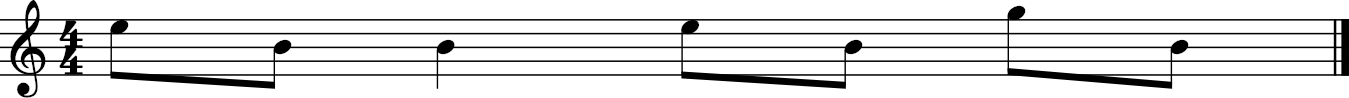

In [3]:
# Definition of the path to MIDI file
midi_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irishtunes_dataset/Cooley's_0_2bars_25.midi"
#midi_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/synthetics_dataset/1.midi"

# Extract frp from 2nd bar
_, _, frp = process_bars(midi_path)

# print(frp)

2nd step: from curve to spline

In [4]:
# Define the spline parameters
x = np.linspace(0, 1, len(frp))
y = frp
control_points = 12 # Number of control points
k = 3  # Spline degree
num_internal_knots = control_points - k - 1 # 12-3-1 = 8 internal knots
t_internal = np.linspace(0, 1, num_internal_knots + 2)[1:-1]  # Internal knots vector
# Make the knot vector (k+1)-regular by adding boundary knots
t = np.r_[(x[0],)*(k+1),
          t_internal,
          (x[-1],)*(k+1)]

# Fit the spline
spline = make_lsq_spline(x, y, t, k)

# Evaluate spline
xs = np.linspace(0, 1, 512)
ys = spline(xs)

In [5]:
t, c, k = spline.t, spline.c, spline.k
print(t, c, k)
print(len(t))

[0.         0.         0.         0.         0.11111111 0.22222222
 0.33333333 0.44444444 0.55555556 0.66666667 0.77777778 0.88888889
 1.         1.         1.         1.        ] [ 0.15493904  0.04652177 -0.22056091 -0.34247481 -0.17686921 -0.15602815
  0.31317482 -0.31351178  0.00911554  0.50915532 -0.1195253   0.12609356] 3
16


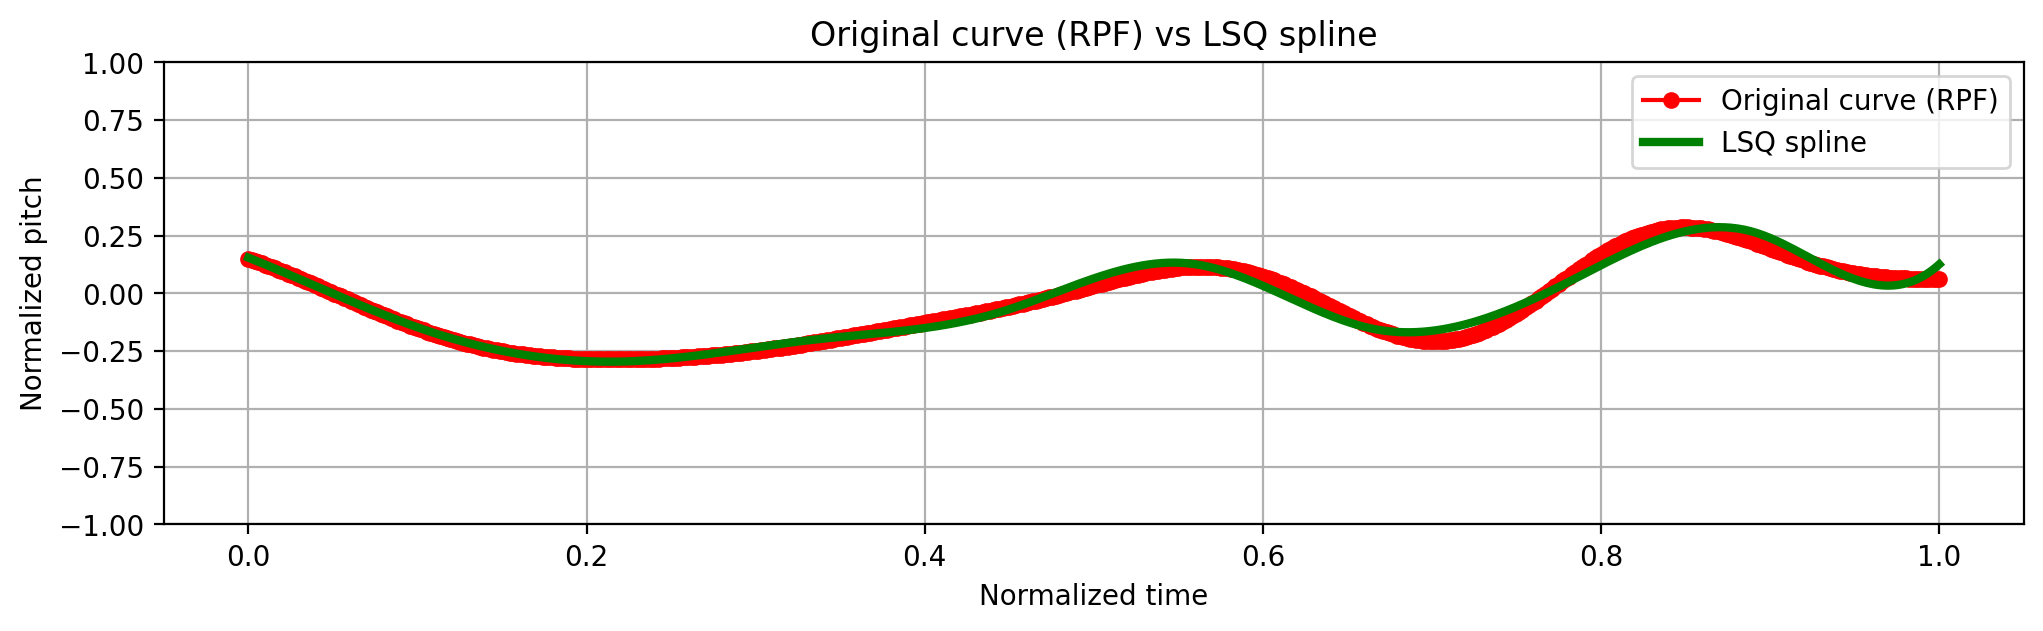

In [6]:
# Plot the results
plt.figure(figsize=(12,3))
plt.plot(x, y, 'ro-', ms=5, label='Original curve (RPF)')
plt.plot(xs, ys, 'g-', lw=3, label='LSQ spline')
plt.legend(loc='best')
plt.xlabel('Normalized time')
plt.ylabel("Normalized pitch")
plt.ylim(-1, 1)
plt.title('Original curve (RPF) vs LSQ spline')
plt.grid(True)
plt.show()

3rd step: from spline to input vector

In [7]:
xxs = np.linspace(0, 1, 256)

input = spline.derivative(1)(xxs)

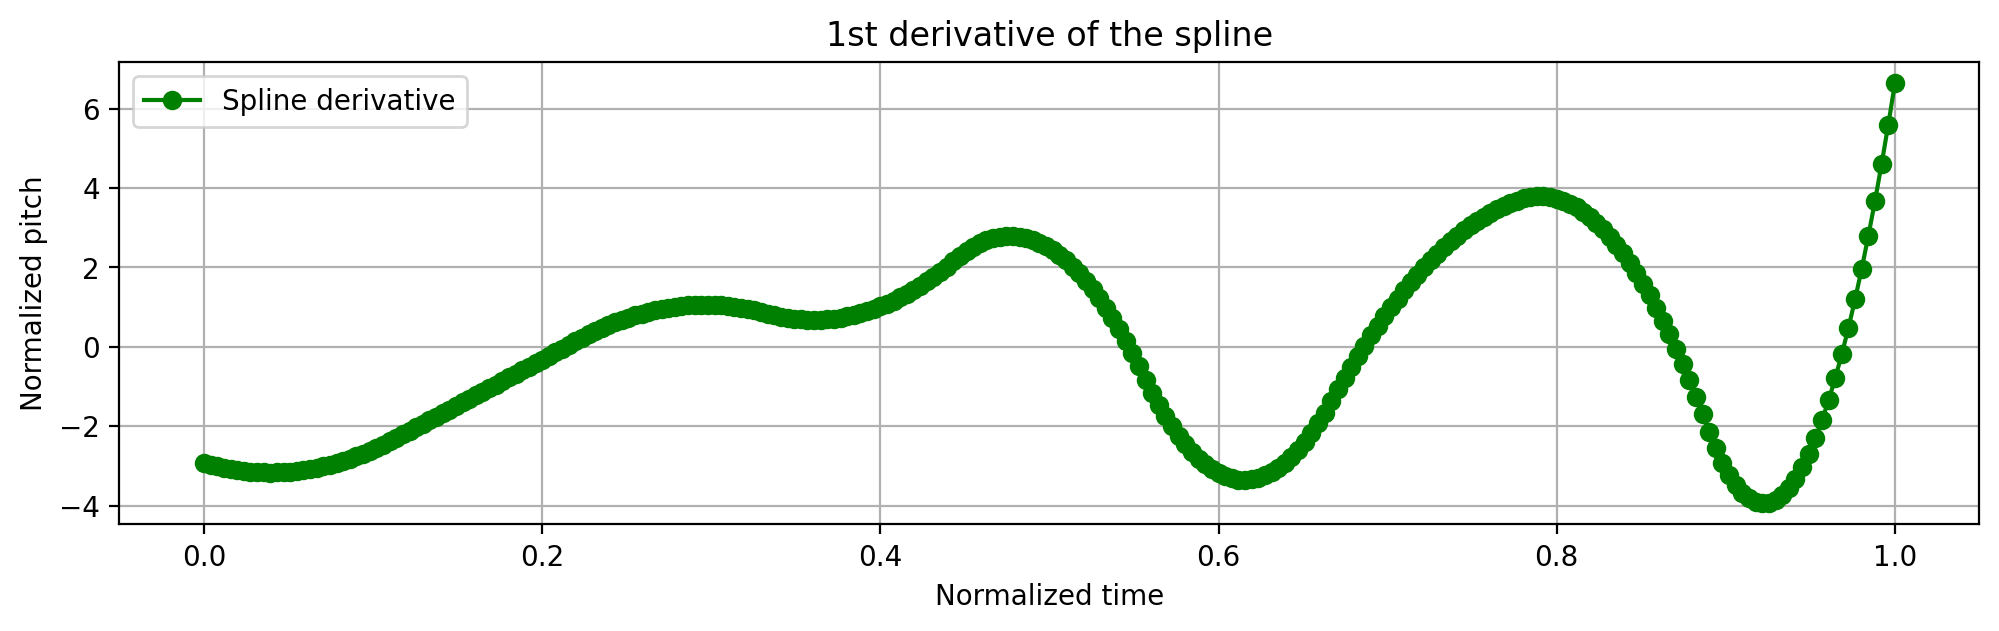

In [8]:
# Plot the results
plt.figure(figsize=(12,3))
plt.plot(xxs, input, '-go', label='Spline derivative')
plt.legend(loc='best')
plt.xlabel('Normalized time')
plt.ylabel("Normalized pitch")
plt.title('1st derivative of the spline')
plt.grid(True)
plt.show()

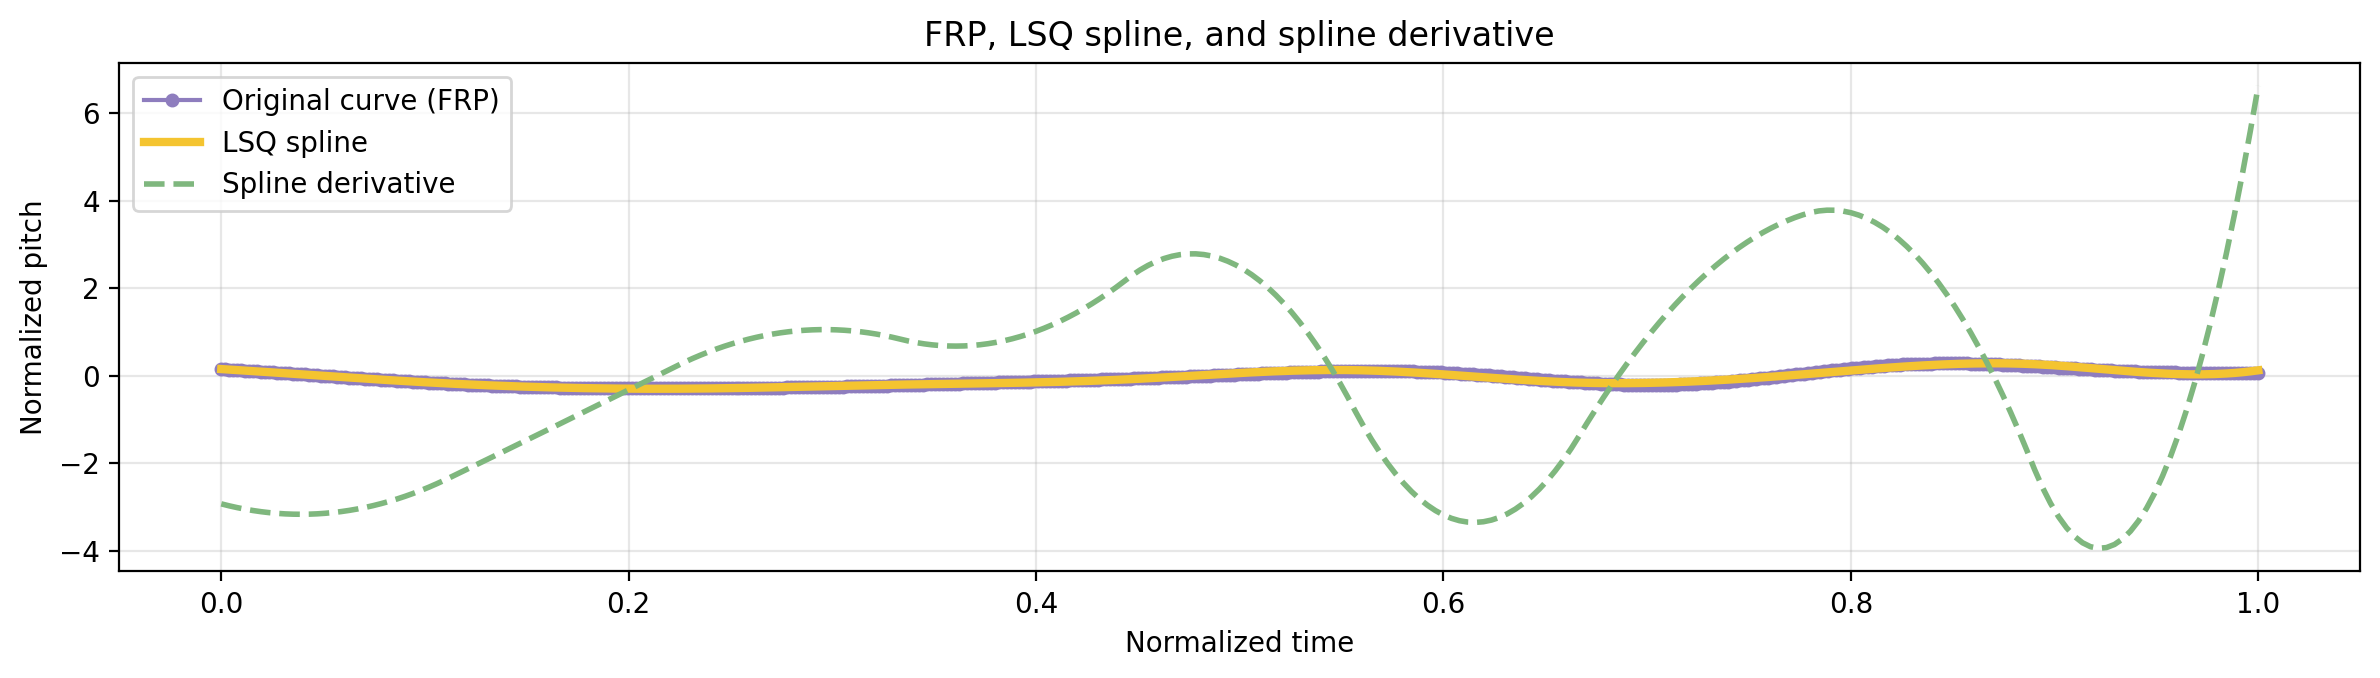

In [9]:
color_frp = '#8E7DBE'
color_dev = '#7FB77E'
color_spline = '#F4C430'

plt.figure(figsize=(12, 3.5))

# FRP
plt.plot(x, y, 'o-',
         color=color_frp,
         ms=4,
         lw=1.5,
         label='Original curve (FRP)')

# LSQ spline
plt.plot(xs, ys, '-',
         color=color_spline,
         lw=3,
         label='LSQ spline')

# Derivative
plt.plot(xxs, input, '--',
         color=color_dev,
         lw=2,
         label='Spline derivative')

plt.xlabel('Normalized time')
plt.ylabel('Normalized pitch')
plt.title('FRP, LSQ spline, and spline derivative')
plt.legend(loc='best')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


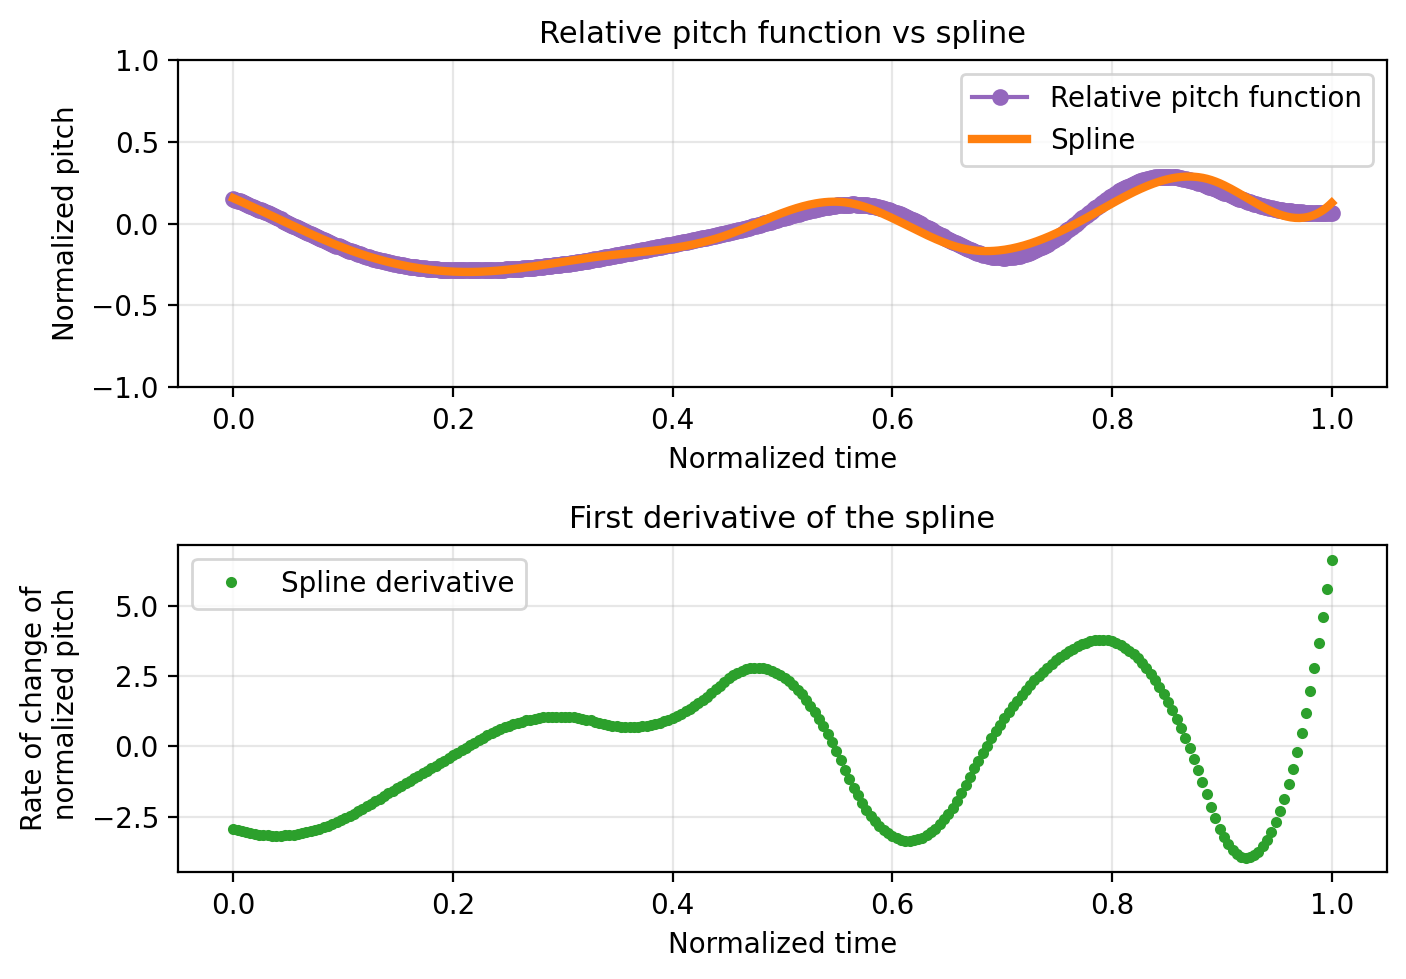

In [10]:
color_frp = 'tab:purple' #'#8E7DBE' #'#6FA8DC' 
color_dev = 'tab:green' #'#7FB77E'
color_spline = 'tab:orange' #"#DDB22F"

fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=False)

# Subplot 1: FRP vs Spline
axes[0].plot(x, y, 'o-',
             color=color_frp,
             ms=5,
             lw=1.5,
             label='Relative pitch function')

axes[0].plot(xs, ys, '-',
             color=color_spline,
             lw=3,
             label='Spline')

axes[0].set_ylabel('Normalized pitch', fontsize=10)
axes[0].set_xlabel('Normalized time', fontsize=10)
axes[0].set_ylim(-1, 1)
axes[0].set_title('Relative pitch function vs spline', fontsize=11)
axes[0].legend(loc='best', fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].tick_params(axis='both', labelsize=10)

# Subplot 2: Derivative
axes[1].plot(xxs, input, 'o',
             color=color_dev,
             ms=3,
             lw=2,
             label='Spline derivative')

axes[1].set_xlabel('Normalized time', fontsize=10)
axes[1].set_ylabel('Rate of change of\n normalized pitch', fontsize=10)
axes[1].set_title('First derivative of the spline', fontsize=11)
axes[1].legend(loc='best', fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].tick_params(axis='both', labelsize=10)

plt.tight_layout()
#plt.show()
plt.savefig("figure.svg", bbox_inches="tight")
